# Blockpose — Point-Cloud Block Detector Showcase

**Python-first prototype track.** This notebook showcases the Phase-A pipeline for
6-DoF pose estimation of concrete blocks (0.6 × 0.6 × 0.9 m) from LiDAR point clouds:

1. **Synthetic scene generation** — Open3D raycasting of box meshes → partial-visibility
   point clouds with *exact* ground truth (no physics engine, fast & faithful).
2. **The detector** — plane-based `DetectFree`: voxel downsample → ground removal →
   clustering → per-cluster plane fit → closed-form pose.
3. **Symmetry-aware evaluation** — Hungarian matching + 4-fold-symmetry rotation error.
4. **The regression gate** — the machine-checkable Phase-A acceptance metric.

> Blocks are full **6-DoF** (they tilt a few degrees on uneven ground); gravity is a
> *prior*, not a constraint. See `docs/detector-plan.md`.


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "python"))
sys.path.insert(0, str(REPO_ROOT / "tools"))

from blockpose.synth import BlockSpec, SynthParams, generate_scene, random_scene
from blockpose.detection import DetectionParams, detect_blocks
from blockpose.evaluate import evaluate
print("imports ok")


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


imports ok


## Plotting helpers

Simple matplotlib 3D rendering so the notebook renders inline anywhere (no GUI window):
point cloud coloured by height, ground-truth boxes in green, detected boxes in blue.


In [2]:
def _box_edges(center, R, dims):
    """12 edges of a posed cuboid -> list of (2,3) segments in world frame."""
    dims = np.asarray(dims, float)
    signs = np.array([[sx, sy, sz] for sx in (-1, 1) for sy in (-1, 1) for sz in (-1, 1)])
    corners = (R @ (signs * dims / 2.0).T).T + np.asarray(center, float)
    edges = [(i, j) for i in range(8) for j in range(i + 1, 8)
             if bin(i ^ j).count("1") == 1]
    return [np.stack([corners[i], corners[j]]) for i, j in edges]


def _draw_boxes(ax, poses, color, label):
    first = True
    for p in poses:
        for seg in _box_edges(p.position, p.rotation, (0.6, 0.6, 0.9)):
            ax.plot(*seg.T, color=color, lw=2.6, label=label if first else None, zorder=5)
            first = False


def _focus(pts, gt, det, margin):
    """Return (center, half_width) of a cube focused on the blocks, not the whole ground."""
    refs = [p.position for p in (gt or [])] + [p.position for p in (det or [])]
    if refs:
        refs = np.asarray(refs)
        ctr = refs.mean(0)
        reach = float((np.abs(refs - ctr).max(0)).max()) + 0.55  # + block half-diagonal
    else:
        ctr = pts.mean(0)
        reach = 1.5
    return ctr, reach + margin


def show_scene(pts, gt=None, det=None, title="", elev=24, azim=-62, margin=0.7, subsample=14000):
    """Zoomed 3D view centred on the blocks: crop faraway ground so the block fills the frame."""
    ctr, half = _focus(pts, gt, det, margin)
    keep = ((np.abs(pts[:, 0] - ctr[0]) < half) &
            (np.abs(pts[:, 1] - ctr[1]) < half) &
            (pts[:, 2] < ctr[2] + half))
    p = pts[keep]
    if len(p) > subsample:
        p = p[np.random.default_rng(0).choice(len(p), subsample, replace=False)]

    fig = plt.figure(figsize=(8.5, 6.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap="turbo", s=8, alpha=0.75,
               depthshade=False)
    if gt:
        _draw_boxes(ax, gt, "#00e000", "ground truth")
    if det:
        _draw_boxes(ax, det, "#1e78ff", "detected")

    zmax = max(1.0, float(ctr[2] + half))
    ax.set_xlim(ctr[0] - half, ctr[0] + half)
    ax.set_ylim(ctr[1] - half, ctr[1] + half)
    ax.set_zlim(0, zmax)
    ax.set_box_aspect((2 * half, 2 * half, zmax))  # true metric proportions
    ax.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]", title=title)
    ax.view_init(elev=elev, azim=azim)
    _, labels = ax.get_legend_handles_labels()
    if labels:
        ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

print("helpers ready")

helpers ready


## 1. Generate a synthetic scene

One block, viewed obliquely from an elevated sensor — so only the top and one/two side
faces are hit, exactly like the real Seyond LiDAR on the crane.


60200 points, 1 ground-truth block(s)
z-range [-0.03, 0.92] m  (block is 0.9 m tall)


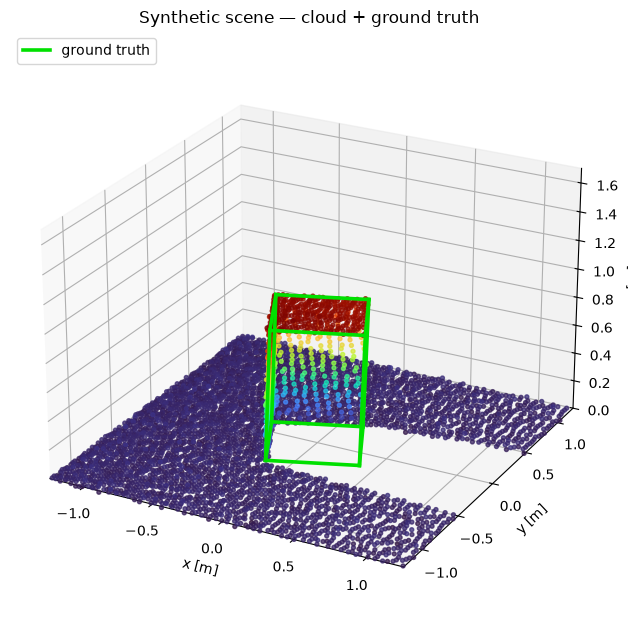

In [3]:
rng = np.random.default_rng(3)
pts, gt = generate_scene(
    [BlockSpec(x=0.0, y=0.0, yaw_deg=25.0, pitch_deg=2.0, roll_deg=-1.5)],
    SynthParams(range_noise_std=0.01),
    rng,
)
print(f"{len(pts)} points, {len(gt)} ground-truth block(s)")
print(f"z-range [{pts[:,2].min():.2f}, {pts[:,2].max():.2f}] m  (block is 0.9 m tall)")
show_scene(pts, gt=gt, title="Synthetic scene — cloud + ground truth")


## 2. Run the detector

`detect_blocks` runs the full plane-based pipeline and returns a `BlockPose` per block.


detected 1 block(s)
  pos=[-0.011, 0.009, 0.539]  source=plane_fit  conf=1.00

ground truth:
  pos=[0.0, 0.0, 0.45]


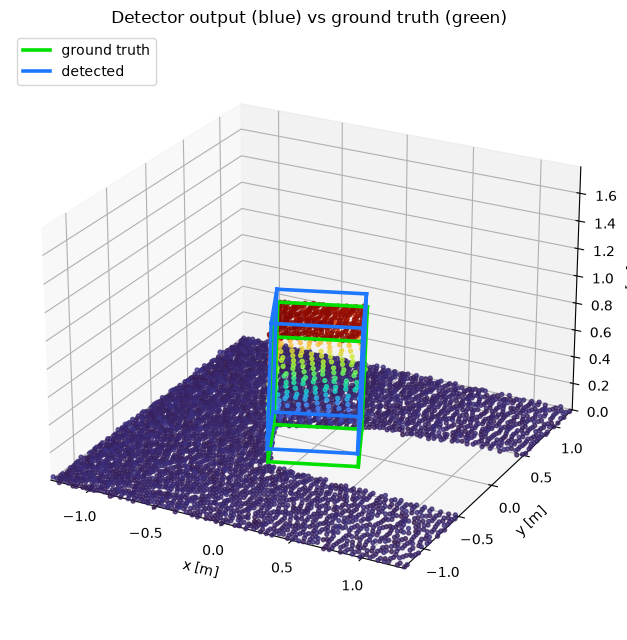

In [4]:
det = detect_blocks(pts, DetectionParams())
print(f"detected {len(det)} block(s)")
for d in det:
    print(f"  pos={np.round(d.position,3).tolist()}  source={d.source}  conf={d.confidence:.2f}")
print("\nground truth:")
for g in gt:
    print(f"  pos={np.round(g.position,3).tolist()}")
show_scene(pts, gt=gt, det=det, title="Detector output (blue) vs ground truth (green)")


## 3. Symmetry-aware evaluation

Because the block has a square cross-section, rotation error is minimised over the 4
yaw-symmetric orientations.


In [5]:
res = evaluate(det, gt, max_match_dist=0.5)
print(f"matched            : {res.matched}/{len(gt)}")
print(f"translation error  : {res.mean_translation_m*1000:.0f} mm")
print(f"rotation error     : {res.mean_rotation_deg:.2f} deg")


matched            : 1/1
translation error  : 90 mm
rotation error     : 0.12 deg


## 4. A harder scene — multiple blocks, tilt & noise

Denser scenes bring mutual occlusion: distant/edge-on blocks are seen too grazing for the
current plane classifier. This is the **Phase-C** frontier (tracked as a diagnostic, below).


4 blocks -> detected 2, matched 2, t_err 94 mm, r_err 0.29 deg


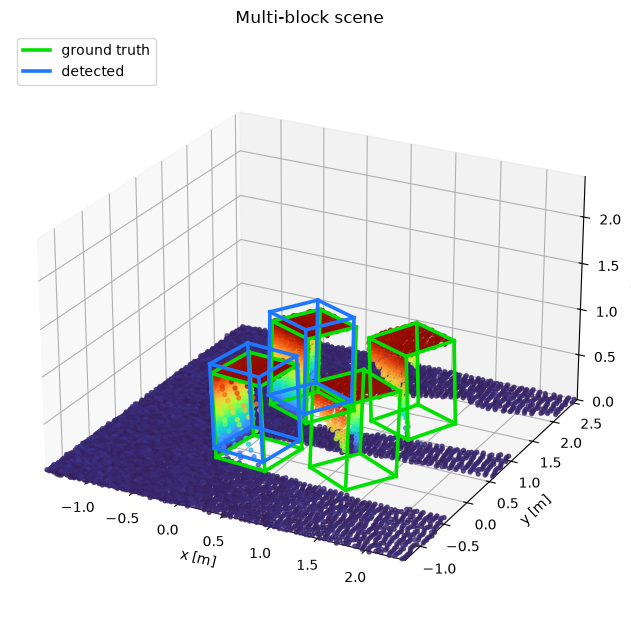

In [6]:
pts_m, gt_m = random_scene(4, SynthParams(range_noise_std=0.01), np.random.default_rng(4))
det_m = detect_blocks(pts_m, DetectionParams())
res_m = evaluate(det_m, gt_m, max_match_dist=0.5)
print(f"{len(gt_m)} blocks -> detected {len(det_m)}, matched {res_m.matched}, "
      f"t_err {res_m.mean_translation_m*1000:.0f} mm, r_err {res_m.mean_rotation_deg:.2f} deg")
show_scene(pts_m, gt=gt_m, det=det_m, title="Multi-block scene")


## 5. The regression gate

`tools/eval_detector.py` runs the detector over a deterministic synthetic suite and gates
on the thresholds in `config/detector_eval.yaml`. Isolated blocks are gated; multi-block
occlusion recall is reported as an ungated **diagnostic** (Phase-C tracking).


In [7]:
import json
import eval_detector

metrics = eval_detector.run_suite(seed=0)
print(json.dumps(metrics, indent=2))


{
  "seed": 0,
  "n_scenes": 8,
  "total_gt": 8,
  "total_detected": 8,
  "total_matched": 8,
  "recall": 1.0,
  "precision": 1.0,
  "translation_mean_m": 0.0975958479389909,
  "translation_p95_m": 0.10982611567811941,
  "rotation_mean_deg": 0.21388098637195435,
  "rotation_p95_deg": 0.2998689668096724,
  "false_positives_empty": 0,
  "diagnostics_multiblock": {
    "n_scenes": 3,
    "total_gt": 9,
    "total_detected": 6,
    "total_matched": 6,
    "recall": 0.6666666666666666,
    "precision": 1.0,
    "translation_mean_m": 0.12012241374174282,
    "translation_p95_m": 0.20961439896957434,
    "rotation_mean_deg": 0.4032263225945592,
    "rotation_p95_deg": 0.7801895178912747
  }
}


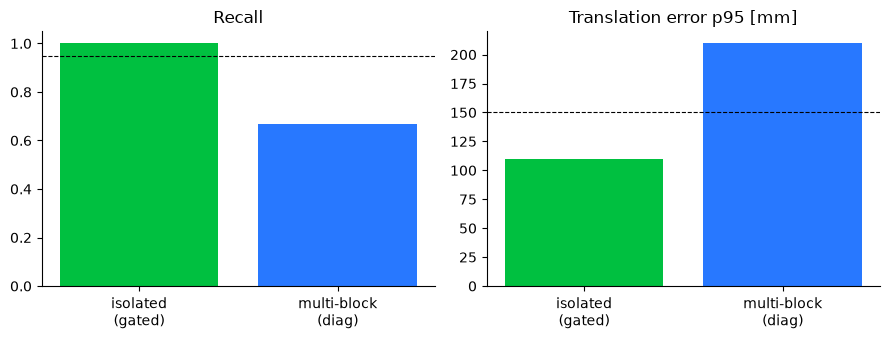

In [8]:
diag = metrics["diagnostics_multiblock"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.5))
a1.bar(["isolated\n(gated)", "multi-block\n(diag)"], [metrics["recall"], diag["recall"]],
       color=["#00c040", "#2878ff"])
a1.set_ylim(0, 1.05); a1.set_title("Recall"); a1.axhline(0.95, ls="--", c="k", lw=0.8)
a2.bar(["isolated\n(gated)", "multi-block\n(diag)"],
       [metrics["translation_p95_m"]*1000, diag["translation_p95_m"]*1000],
       color=["#00c040", "#2878ff"])
a2.set_title("Translation error p95 [mm]"); a2.axhline(150, ls="--", c="k", lw=0.8)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


The dashed lines are the current gate thresholds. Translation error (~0.1 m) is limited
by single-face-centroid bias — **Phase B** (box ICP refine + known-dimension center recovery)
is expected to pull it to a few cm, at which point the threshold ratchets down.
